In [16]:
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.table import Table
from math import sin, cos, tan, radians, sqrt, pi
import os
import subprocess
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.optimize import least_squares

In [2]:
df = pd.read_csv('/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Full_test_catalogue.csv')

# FITS (GRS) example
#l = df['x_cen']
#b = df['y_cen']
#v = df['v_cen'] / 1000

In [3]:
cluster_ids = df['Universal_ID']
cluster_ids = cluster_ids.to_numpy()

df_inp = pd.DataFrame({
    'Source'       : df['Universal_ID'],
    'Long (deg)'   : df['x_cen'],
    'Lat (deg)'    : df['y_cen'],
    'vlsr (km/s)'  : df['v_cen']/1000,
    'v_rms (km/s)' : df['sigv_kms'],
    'P': 0.5
})

In [4]:
## Straight copy from BDC

# Creates the sources.info file in v2.4.1
# Saves necessary file

# Save to .inp file with space-separated columns
output_path = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
output_file = 'sources_info.inp'

with open(output_path+output_file, 'w') as f:
    f.write('! Source Long(deg) Lat(deg) vlsr(km/s) v_rms(km/s) P\n')  # comment line
    df_inp.to_csv(f, sep=' ', index=False, header=False, float_format='%.4f')


# Path to the Fortran executable
exe_path = "/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/distance_calculator"
distance_dir='/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'
os.chdir(distance_dir)

try:
    result = subprocess.run([exe_path], check=True, capture_output=True, text=True)
    print("Program output:")
    print(result.stdout)
except subprocess.CalledProcessError as e:
    print("Error running Fortran program:")
    print(e.stderr)

Program output:
 Bayesian distance estimator: 2019: September 24, 2019

 Reading in file "probability_controls.inp                        "
 Max Prob_SA = 0.85
 Max Prob_KD = 0.85
 Max Prob_GL = 0.85
 Max Prob_PS = 0.15
 Max Prob_PM = 0.85


 Openning input ascii file "galaxy_data_Univ.inp            "
 Comment lines follow:
 ! Galactic and Solar Motion parameters                                          
 ! for use with 2-parameter Persic "Universal" rotation curve                    
 End of Comment lines

 Galaxy model:
  Ro, a1, a2, a3:                         8.15   236.000     0.960     1.620
  Solar Motion (Uo,Vo,Wo):               10.60     10.70      7.60
  Source Peculiar Motion (Us,Vs,Ws):      0.00      0.00      0.00

 Getting Spiral arm segment data:
 

  Read file Out_lbvRBD.2019      containing 176 (l,b,v,R,beta,D) values.
       Spanning longitude range:    0.0 to  252.0 deg.

  Read file Per_lbvRBD.2019      containing 272 (l,b,v,R,beta,D) values.
       Spanning long

In [5]:
def universal_rotation_curve(r, a2, a3, R0):
    """
    Universal Rotation Curve (Persic, Salucci & Stel 1996),
    using the supplied Fortran parameterization.

    Parameters
    ----------
    r : float or array
        Galactocentric radius (kpc)
    a2 : float
        Ropt / R0
    a3 : float
        1.5 * (L/Lstar)**(1/5)
    R0 : float
        Solar Galactocentric radius (kpc)

    Returns
    -------
    theta : float or array
        Circular rotation speed (km/s)
    """

    r = np.asarray(r, dtype=float)

    lam = (a3 / 1.5)**5

    Ropt = a2 * R0
    rho = r / Ropt

    log_lam = np.log10(lam)

    term1 = 200.0 * lam**0.41

    top = 0.75 * np.exp(-0.4 * lam)
    bot = 0.47 + 2.25 * lam**0.4

    term2 = np.sqrt(
        0.80 + 0.49 * log_lam + top / bot
    )

    top = 1.97 * rho**1.22
    bot = (rho**2 + 0.61)**1.43

    term3 = (
        (0.72 + 0.44 * log_lam)
        * (top / bot)
    )

    top = rho**2
    bot = rho**2 + 2.25 * lam**0.4

    term4 = (
        1.6 * np.exp(-0.4 * lam)
        * (top / bot)
    )

    theta = (term1 / term2) * np.sqrt(term3 + term4)

    return theta

In [7]:
# Example URC parameters -- replace with your adopted values
a2 = 0.96
a3 = 1.62
R0 = 8.15
n  = len(df)
dist_method = np.zeros(n, dtype=int)


R      = np.zeros(n)
Vcalc  = np.zeros(n)
d_near = np.zeros(n)
d_far  = np.zeros(n)
d      = np.zeros(n)

theta0 = universal_rotation_curve(R0, a2, a3, R0) ## Correct

R_grid = np.arange(0.5, 25.01, 0.01) ## Correct

theta_grid = universal_rotation_curve(R_grid, a2, a3, R0) ## Correct

# Predicted velocity for a given cloud longitude and latitude
for i in range(n):

    l = np.radians(df["x_cen"][i])
    b = np.radians(df["y_cen"][i])
    V = df["v_cen"][i] / 1000.0

    V_grid = (
        theta_grid * R0 / R_grid - theta0
    ) * np.sin(l) * np.cos(b)

    j = np.argmin(np.abs(V_grid - V))

    R[i] = R_grid[j]
    Vcalc[i] = V_grid[j]


    A = cos(b)**2
    B = 2 * R0 * cos(b) * cos(l)
    C = R0**2 - R[i]**2
    delta = B**2 - 4 * A * C

    if delta <= 0:
        d1 = d2 = R0 * cos(l) / cos(b)
    else:
        sqrt_delta = sqrt(delta)
        d1 = -( -B + sqrt_delta ) / (2 * A)
        d2 = -( -B - sqrt_delta ) / (2 * A)

    d_near[i], d_far[i] = min(d1, d2), max(d1, d2)

    if R[i] >= R0 or d_near[i] <= 0:
        d[i] = d_far[i]
        dist_method[i] = 2  # Outer Galaxy

for i in range(n):
    if dist_method[i] != 0:
        continue
    l = np.radians(df["x_cen"][i])
    V = df["v_cen"][i] / 1000.0
    tan_vel = theta0 * sin(l)
    if abs(V - tan_vel) < 10 and (d_far[i] - d_near[i]) <= 1.0:
        d[i] = (d_near[i] + d_far[i]) / 2
        dist_method[i] = 3  # Tangent method

# Step 3: Scale Height Method
# Still unresolved sources
for i in range(n):
    if dist_method[i] != 0:
        continue
    b = df['y_cen'][i]
    z = d_far[i] * 1000 * tan(b)  # pc
    if abs(z) > 120:
        d[i] = d_near[i]
        dist_method[i] = 4  # Scale height method

df['R_GC'] = R
df['d_near'] = d_near
df['d_far'] = d_far
df['distance'] = d
df['dist_method'] = dist_method

In [8]:
df

,Universal_ID,v_cen,x_cen,y_cen,final_distance,Mass,sigv_kms,has_match,AGAL_distance,R_GC,d_near,d_far,distance,dist_method
0,1,-10123.06,10.673,-0.125,18.66,50600.0,2.25,False,0.0,10.43,-2.311202,18.329253,18.329253,2
1,2,-3890.14,10.099,-0.603,16.99,247000.0,3.23,False,0.0,8.95,-0.811486,16.859827,16.859827,2
2,3,-5324.70,15.617,-0.487,16.59,62600.0,1.52,False,0.0,8.85,-0.724626,16.423442,16.423442,2
3,4,-2425.28,10.544,-0.387,5.00,180000.0,1.85,True,5.0,8.61,-0.467479,16.492614,16.492614,2
4,5,3355.82,11.444,-0.357,0.52,2480.0,3.49,False,0.0,7.63,0.531301,15.444950,0.531301,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1781,1782,1760.26,354.893,0.106,16.97,14700.0,1.58,False,0.0,8.85,-0.702569,16.937889,16.937889,2
1782,1783,2720.37,354.916,0.168,17.45,51100.0,1.64,False,0.0,9.29,-1.143952,17.379895,17.379895,2
1783,1784,2725.99,354.203,0.320,1.30,15900.0,1.41,True,1.3,9.14,-0.994550,17.211444,17.211444,2
1784,1785,7492.74,353.088,-0.124,19.21,31900.0,1.58,False,0.0,10.85,-2.714817,18.896389,18.896389,2


In [9]:
# Function definition
# Run fearlessly

def determine_distance_assignment(txt_path, d_near, d_far):
    components = []

    with open(txt_path, 'r') as f:
        lines = f.readlines()

    # Filter lines that contain "Probability component"
    prob_lines = [line.strip() for line in lines if line.strip().startswith("Probability component")]

    for line in prob_lines:
        parts = line.split()
        try:
            dist = float(parts[3])
            prob = float(parts[5])
            components.append((dist, prob))
        except (IndexError, ValueError):
            continue

    if not components:
        raise ValueError("No valid probability components found.")

    # Get distance of component with highest probability
    best_dist, _ = max(components, key=lambda x: x[1])
    #print(best_dist)
    
    all_distances = [comp[0] for comp in components]
    min_distance = min(all_distances)
    max_distance = max(all_distances)

    if abs(best_dist - d_near) <= abs(best_dist - d_far):
            return 'near'
    else:
            return 'far'

prt_dir = '/Users/kyriakos.trakakis/Downloads/v2.4.1_bundle/'  # Update if needed
final_distances = []
distance_flags = []  # Optional: stores 'near' or 'far'

In [10]:
# Selects near or far distances
# Run fearlessly

for idx, row in df.iterrows():
    obj_id = int(row['Universal_ID'])
    prt_file = os.path.join(prt_dir, f"{obj_id}.prt")

    if row['R_GC'] < R0:

        try:
            choice = determine_distance_assignment(prt_file, row['d_near'], row['d_far'])
            if choice == 'near':
                final_distances.append(row['d_near'])
                distance_flags.append('near')
            else:
                final_distances.append(row['d_far'])
                distance_flags.append('far')
        except Exception as e:
            print(f"Warning: Failed to process {prt_file} due to {e}")
            final_distances.append(np.nan)
            distance_flags.append('error')

    else:
        final_distances.append(row['d_far'])
        distance_flags.append('No_KDA')

df['distance'] = final_distances
df['distance_flag'] = distance_flags  # Optional for debugging
#df['structure_type'] = df['structure_type'].str.decode('utf-8').str.strip() 

In [11]:
# Chooses between AGAL distance for clusters with matches and best distance for those without
# Looks like AGAL distances are strings! turn them to floats first.
# Run fearlessly

final_distance = []
for i in range(len(df)):
    if df['has_match'][i] and df['AGAL_distance'][i] != '---':
        final_distance.append(float(df['AGAL_distance'][i]))
    else:
        final_distance.append(df['distance'][i])

df['final_distance_new'] = final_distance

In [ ]:
## See what points don't have final_distance and final_distance_new in agreement

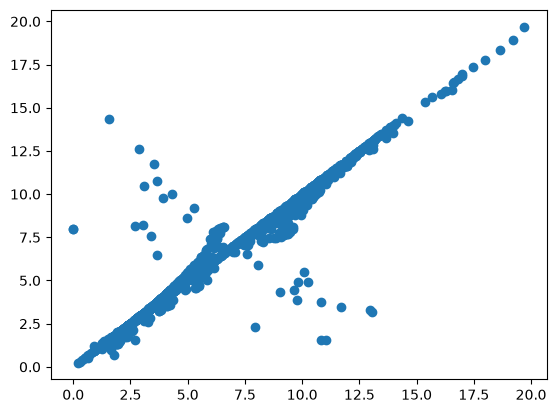

In [12]:
plt.scatter(df['final_distance'], df['final_distance_new'])

In [13]:
df.columns

Index(['Universal_ID', 'v_cen', 'x_cen', 'y_cen', 'final_distance', 'Mass',
       'sigv_kms', 'has_match', 'AGAL_distance', 'R_GC', 'd_near', 'd_far',
       'distance', 'dist_method', 'distance_flag', 'final_distance_new'],
      dtype='str')

# MW Spiral arms from here on

In [62]:
R0 = 8.15

mask = (df['Mass'] / df['final_distance_new'] ** 2) > 75.7
#mask = df_2['Mass'] > 10 ** 4

df = df[mask]

l = np.radians(df["x_cen"].to_numpy())
b = np.radians(df["y_cen"].to_numpy())
d = df["final_distance_new"].to_numpy()

X = d * np.cos(b) * np.sin(l)
Y = R0 - d * np.cos(b) * np.cos(l)

R = np.hypot(X, Y)

# Reid azimuth convention
beta = np.degrees(np.arctan2(X, Y))

df["X_kpc"] = X
df["Y_kpc"] = Y
df["R_kpc"] = R
df["beta_deg"] = beta
df["ln_R"] = np.log(R)

In [63]:
# Old function from Mopra_spiral_arms_Reid.py

def reid_arm(name, n=2000, extend_low=0, extend_high=0,
             params=None):

    if params is None:
        params = parameters

    bmin, bmax, bkink, Rkink, p_low, p_high = params[name]

    beta = np.linspace(
        bmin - extend_low,
        bmax + extend_high,
        n
    )

    pitch = np.where(beta <= bkink, p_low, p_high)

    R = Rkink * np.exp(
        -np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )

    X = R * np.sin(np.radians(beta))
    Y = R * np.cos(np.radians(beta))

    original = (beta >= bmin) & (beta <= bmax)

    return {
        "beta": beta,
        "R": R,
        "X": X,
        "Y": Y,
        "original": original
    }

parameters = {
    "3-kpc":   (15, 18, 15, 3.52, -4.2, -4.2),
    "Norma":   (5, 54, 18, 4.46, -1.0, 19.5),
    "Sct-Cen": (0, 104, 23, 4.91, 14.1, 12.1),
    "Sgr-Car": (2, 97, 24, 6.04, 17.1, 1.0),
    "Local":   (-8, 34, 9, 8.26, 11.4, 11.4),
    "Perseus": (-23, 115, 40, 8.87, 10.3, 8.7),
    "Outer":   (-16, 71, 18, 12.24, 3.0, 9.4),
}

# Fill these with verified Reid (2019) width values, in kpc
arm_widths = {
    "Norma": 0.14,
    "Sct-Cen" : 0.23,
    "Sgr-Car" : 0.27,
    "Perseus" : 0.35,
    "3-kpc"   : 0.18
}

In [64]:
# Assigning clouds to arms using KD Tree

arm_names = ["Norma", "Sct-Cen", "Sgr-Car", "Perseus", "3-kpc"]

colours = {
    "Norma": "red",
    "Sct-Cen": "blue",
    "Sgr-Car": "purple",
    "Perseus": "black",
    "3-kpc": "orange"
}

# Generate all four arms
extended_arms = {
    name: reid_arm(
        name,
        extend_low  = 130,
        extend_high =130
    )
    for name in arm_names
}

# Catalogue coordinates
cloud_xy = df[["X_kpc", "Y_kpc"]].to_numpy(dtype=float)  # Collect the coordinates of each cloud on the (X,Y) Galactic plane
valid = np.isfinite(cloud_xy).all(axis=1)

# Calculate distances to each arm
for name, arm in extended_arms.items():

    arm_xy = np.column_stack([
        arm["X"],
        arm["Y"]
    ])  # Collect the points making up each arm on the Galactic plane

    tree = cKDTree(arm_xy)  # Create the KD tree

    distances = np.full(len(df), np.nan)

    distances[valid], _ = tree.query(cloud_xy[valid]) 
    # distances: the distance, in kpc, from each cloud to the nearest sampled point on that arm.
    # indices: the index of that nearest arm point within arm_xy.

    df[f"dist_{name}_kpc"] = distances

# Identify nearest arm
distance_columns = [
    f"dist_{name}_kpc" for name in arm_names
]

distance_matrix = df[distance_columns].to_numpy()

closest_index = np.full(len(df), -1, dtype=int)
closest_distance = np.full(len(df), np.nan)

closest_index[valid] = np.argmin(
    distance_matrix[valid], axis=1  # Find arm with lowest distance
)                                  

closest_distance[valid] = np.min(
    distance_matrix[valid], axis=1
)

df["nearest_arm"] = [
    arm_names[i] if i >= 0 else None
    for i in closest_index
]

df["arm_distance_kpc"] = closest_distance

# Apply an initial association threshold
# Clouds will not be associated if their distance is higher than this, 3 * width
n_sigma = 3.0

df["assigned_arm"] = "Unassigned"

for name in arm_names:

    mask = (
        (df["nearest_arm"] == name)
        & (df["arm_distance_kpc"] <= n_sigma * arm_widths[name])
    )

    df.loc[mask, "assigned_arm"] = name

print(df["assigned_arm"].value_counts())

assigned_arm
Sct-Cen       539
Sgr-Car       357
Unassigned    221
Norma         179
3-kpc         103
Perseus        71
Name: count, dtype: int64


In [65]:
# Issue discovered later: Turn azimuth to 360 degrees to avoid problems
# Preserve the original wrapped azimuths
df["beta_unwrapped_deg"] = df["beta_deg"].copy()

# Record the winding number for diagnostic purposes
df["beta_winding"] = np.nan

for name in arm_names:

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["X_kpc"])
        & np.isfinite(df["Y_kpc"])
        & np.isfinite(df["beta_deg"])
    ]

    if subset.empty:
        continue

    # Original extended Reid curve
    arm = extended_arms[name]

    arm_xy = np.column_stack([
        arm["X"],
        arm["Y"]
    ])

    arm_beta = np.asarray(arm["beta"])

    # Remove any invalid arm points
    valid = (
        np.isfinite(arm_xy).all(axis=1)
        & np.isfinite(arm_beta)
    )

    arm_xy = arm_xy[valid]
    arm_beta = arm_beta[valid]

    if len(arm_beta) == 0:
        continue

    # Find nearest Reid-arm point for each cloud
    tree = cKDTree(arm_xy)

    cloud_xy = subset[["X_kpc", "Y_kpc"]].to_numpy()

    distances, indices = tree.query(cloud_xy)

    beta_nearest = arm_beta[indices]

    # Cloud's original wrapped azimuth
    beta_wrapped = subset["beta_deg"].to_numpy()

    # Find the integer winding that matches the Reid arm
    winding = np.rint(
        (beta_nearest - beta_wrapped) / 360.0
    ).astype(int)

    # Corrected cloud azimuth
    beta_unwrapped = beta_wrapped + 360.0 * winding

    # Store results
    df.loc[
        subset.index, "beta_unwrapped_deg"
    ] = beta_unwrapped

    df.loc[
        subset.index, "beta_winding"
    ] = winding

In [66]:
## Add arm asssignments and distances to the dataframe

# Distances already calculated using KD-trees
distance_columns = [f"dist_{name}_kpc" for name in arm_names]

distance_matrix = df[distance_columns].to_numpy(dtype=float)

width_array = np.array([arm_widths[name] for name in arm_names])

# Normalize by arm width
normalized_distances = distance_matrix / width_array[None, :]

# Save normalized distances, called z
for j, name in enumerate(arm_names):
    df[f"z_{name}"] = normalized_distances[:, j]

# Check

valid = np.isfinite(normalized_distances).all(axis=1)

best_index = np.full(len(df), -1, dtype=int)
best_z = np.full(len(df), np.nan)

best_index[valid] = np.argmin(
    normalized_distances[valid],
    axis=1
)

best_z[valid] = np.min(
    normalized_distances[valid],
    axis=1
)

df["assigned_arm"] = "Unassigned"
df["arm_z"] = best_z

for j, name in enumerate(arm_names):
    mask = (best_index == j) & (best_z <= n_sigma)
    df.loc[mask, "assigned_arm"] = name

print(df["assigned_arm"].value_counts())

# Check

sorted_z = np.sort(normalized_distances, axis=1)

df["second_best_z"] = np.where(
    valid, sorted_z[:, 1], np.nan
)

df["arm_separation_z"] = (
    df["second_best_z"] - df["arm_z"]
)

print(
    df[
        ["Universal_ID", "assigned_arm",
         "arm_z", "second_best_z", "arm_separation_z"]
    ].head(10)
)
# Measure if 2 arms well approach a source. A large arm_separation means a good first choice.

assigned_arm
Sct-Cen       555
Sgr-Car       357
Unassigned    206
Norma         164
3-kpc         109
Perseus        79
Name: count, dtype: int64
    Universal_ID assigned_arm      arm_z  second_best_z  arm_separation_z
0              1   Unassigned  11.374002      17.172301          5.798299
1              2   Unassigned   7.152907      11.689219          4.536312
2              3   Unassigned   6.340369      11.248940          4.908571
3              4        3-kpc   0.898390       7.088126          6.189735
4              5      Sgr-Car   2.803604       6.753675          3.950071
5              6      Sct-Cen   2.133326       2.150268          0.016942
6              7      Sgr-Car   0.365999       6.419067          6.053068
7              8   Unassigned   3.202878       6.440000          3.237123
8              9      Sgr-Car   2.035863       7.360159          5.324297
10            11      Sgr-Car   0.895633       4.853803          3.958170


In [67]:
indices = [1385, 1759, 1765, 1604, 1606]

arm = extended_arms["Perseus"]

arm_xy = np.column_stack([arm["X"], arm["Y"]])
arm_beta = np.asarray(arm["beta"])

valid = np.isfinite(arm_xy).all(axis=1) & np.isfinite(arm_beta)

tree = cKDTree(arm_xy[valid])

cloud_xy = df.loc[indices, ["X_kpc", "Y_kpc"]].to_numpy()

distances, nearest_indices = tree.query(cloud_xy)

beta_nearest = arm_beta[valid][nearest_indices]
beta_wrapped = df.loc[indices, "beta_deg"].to_numpy()

winding = np.rint(
    (beta_nearest - beta_wrapped) / 360.0
).astype(int)

print(
    pd.DataFrame({
        "beta_wrapped": beta_wrapped,
        "beta_nearest_arm": beta_nearest,
        "winding": winding,
        "distance_kpc": distances
    }, index=indices)
)

indices = [1385, 1759, 1765, 1604, 1606]

# Assign the windings calculated in the diagnostic
df.loc[indices, "beta_winding"] = winding

# Update their unwrapped azimuths
df.loc[indices, "beta_unwrapped_deg"] = (
    df.loc[indices, "beta_deg"]
    + 360.0 * df.loc[indices, "beta_winding"]
)

# Verify the dataframe was updated
print(
    df.loc[
        indices,
        ["beta_deg", "beta_unwrapped_deg", "beta_winding", "arm_separation_z"]
    ]
)

      beta_wrapped  beta_nearest_arm  winding  distance_kpc
1385   -104.097836        245.000000        1      0.988417
1759   -163.070064        198.808904        1      1.058086
1765     -3.603543          7.275138        0      5.121866
1604   -135.720771        226.085543        1      0.909541
1606   -135.283284        226.284642        1      0.854134
        beta_deg  beta_unwrapped_deg  beta_winding  arm_separation_z
1385 -104.097836          255.902164           1.0          3.810206
1759 -163.070064          196.929936           1.0          0.568966
1765   -3.603543           -3.603543           0.0          0.644294
1604 -135.720771          224.279229           1.0          1.780065
1606 -135.283284          224.716716           1.0          1.750503


In [89]:
indices = [1545, 1568, 1573]

arm = extended_arms["Sct-Cen"]

arm_xy = np.column_stack([arm["X"], arm["Y"]])
arm_beta = np.asarray(arm["beta"])

valid = np.isfinite(arm_xy).all(axis=1) & np.isfinite(arm_beta)

tree = cKDTree(arm_xy[valid])

cloud_xy = df.loc[indices, ["X_kpc", "Y_kpc"]].to_numpy()

distances, nearest_indices = tree.query(cloud_xy)

beta_nearest = arm_beta[valid][nearest_indices]
beta_wrapped = df.loc[indices, "beta_deg"].to_numpy()

winding = np.rint(
    (beta_nearest - beta_wrapped) / 360.0
).astype(int)

print(
    pd.DataFrame({
        "beta_wrapped": beta_wrapped,
        "beta_nearest_arm": beta_nearest,
        "winding": winding,
        "distance_kpc": distances
    }, index=indices)
)

indices = [1545, 1568, 1573]

# Assign the windings calculated in the diagnostic
df.loc[indices, "beta_winding"] = winding

# Update their unwrapped azimuths
df.loc[indices, "beta_unwrapped_deg"] = (
    df.loc[indices, "beta_deg"]
    + 360.0 * df.loc[indices, "beta_winding"]
)

# Verify the dataframe was updated
print(
    df.loc[
        indices,
        ["beta_deg", "beta_unwrapped_deg", "beta_winding", "arm_separation_z"]
    ]
)

      beta_wrapped  beta_nearest_arm  winding  distance_kpc
1545   -115.529310        234.000000        1      0.509477
1568   -123.511182        234.000000        1      0.502014
1573   -124.847099        232.543272        1      0.619098
        beta_deg  beta_unwrapped_deg  beta_winding  arm_separation_z
1545 -115.529310          244.470690           1.0          0.446897
1568 -123.511182          236.488818           1.0          0.572755
1573 -124.847099          235.152901           1.0          0.179262


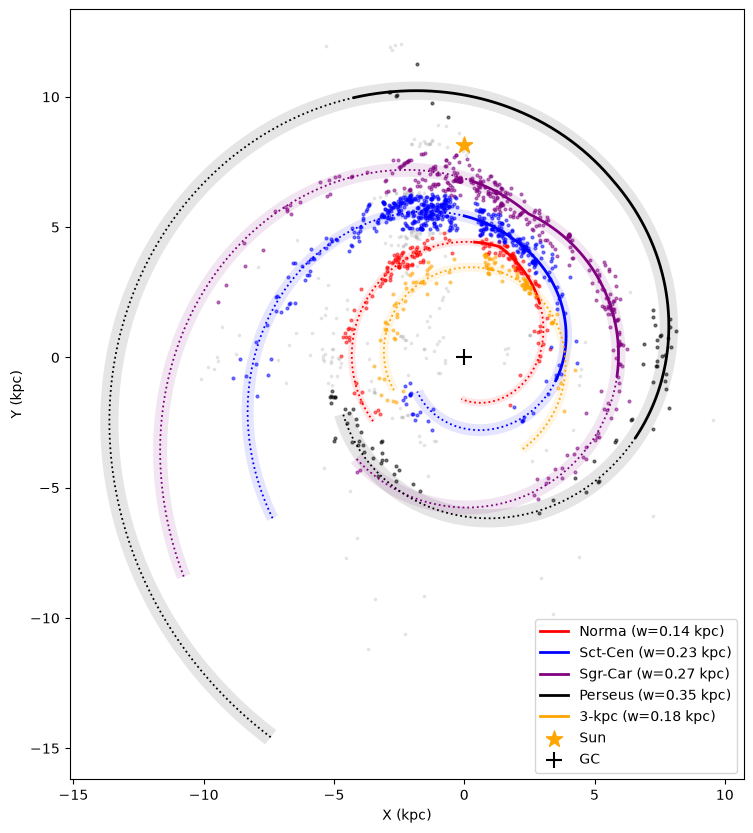

In [90]:
# Plot arms assignment ver.1

fig, ax = plt.subplots(figsize=(10, 10))

for name, arm in extended_arms.items():

    beta = arm["beta"]
    X = arm["X"]
    Y = arm["Y"]

    bmin, bmax, *_ = parameters[name]

    original = (beta >= bmin) & (beta <= bmax)
    extension_low = beta < bmin
    extension_high = beta > bmax

    # Arm width (kpc)
    w = arm_widths[name]

    # Tangent vector along the spiral
    dx = np.gradient(X)
    dy = np.gradient(Y)

    length = np.hypot(dx, dy)

    # Unit normal vector
    nx = -dy / length
    ny = dx / length

    # Boundaries at +/- one arm width
    X_upper = X + w * nx
    Y_upper = Y + w * ny

    X_lower = X - w * nx
    Y_lower = Y - w * ny

    # Fill the band between the two boundaries
    band_x = np.concatenate([X_upper, X_lower[::-1]])
    band_y = np.concatenate([Y_upper, Y_lower[::-1]])

    ax.fill(
        band_x,
        band_y,
        color=colours[name],
        alpha=0.10,
        linewidth=0,
        zorder=1
    )

    # Original arm centreline
    ax.plot(
        X[original],
        Y[original],
        color=colours[name],
        lw=2,
        ls="-",
        label=f"{name} (w={w:.2f} kpc)",
        zorder=3
    )

    # Plot extensions separately to avoid artificial connections
    for mask in [extension_low, extension_high]:

        ax.plot(
            X[mask],
            Y[mask],
            color=colours[name],
            lw=1.3,
            ls=":",
            zorder=3
        )

# Catalogue clouds, coloured by assigned arm
for name in arm_names:

    subset = df[df["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.5,
        rasterized=True,
        zorder=4
    )

# Unassigned clouds
unassigned = df[df["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

# Sun and Galactic Centre
ax.scatter(0, R0, marker="*", s=150,
           color="orange", zorder=5, label="Sun")

ax.scatter(0, 0, marker="+", s=120,
           color="black", zorder=5, label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.legend()

plt.show()

In [91]:
## Fit clouds to double Reid arm, with kink and 2 pitch angles

def fit_reid_arm(df, name, parameters, min_points=3):

    bmin, bmax, bkink, Rkink, p_low, p_high = parameters[name] # Looks like we are feeding Rkink, bkink into this and fit for R,b

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ].copy()

    if len(subset) < min_points:
        return None

    # Azimuth relative to Reid kink, in radians
    beta = np.radians(subset["beta_unwrapped_deg"].to_numpy())
    beta_kink = np.radians(bkink)

    x = beta - beta_kink
    y = np.log(subset["R_kpc"].to_numpy())

    # Continuous piecewise-linear model, looks like with high and low we fit for under and over the kink
    x_low = np.minimum(x, 0.0)
    x_high = np.maximum(x, 0.0)

    A = np.column_stack([  ## A has the parameters for both high and low, before and after kink
        np.ones_like(x),
        x_low,
        x_high
    ])   

    # Ordinary least squares for the first experiment
    coefficients, residuals, rank, singular_values = (  ## Fitting for A containing high and low, coefficients are a, mhigh and mlow
        np.linalg.lstsq(A, y, rcond=None)
    )

    if rank < 3:
        return None

    a, m_low, m_high = coefficients

    return {
        "name": name,
        "N": len(subset),
        "Rkink_fit": np.exp(a),
        "pitch_low_fit": np.degrees(np.arctan(-m_low)),
        "pitch_high_fit": np.degrees(np.arctan(-m_high)),
        "Rkink_Reid": Rkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high
    }


fit_results = []

for name in arm_names:

    result = fit_reid_arm(df, name, parameters)
    
    if result is not None:
        fit_results.append(result)

fit_table = pd.DataFrame(fit_results)

print(fit_table.round(3).to_string(index=False))

   name   N  Rkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  pitch_low_Reid  pitch_high_Reid
  Norma 164      4.436         -0.433          19.078        4.46            -1.0             19.5
Sct-Cen 555      4.930         14.239          10.139        4.91            14.1             12.1
Sgr-Car 357      5.963         16.675           0.431        6.04            17.1              1.0
Perseus  79      8.531         12.101           8.537        8.87            10.3              8.7
  3-kpc 109      3.646         -4.516          -1.992        3.52            -4.2             -4.2


In [92]:
## Load fit parameters

fitted_parameters = parameters.copy()

for result in fit_results:

    name = result["name"]

    bmin, bmax, bkink, _, _, _ = parameters[name]

    fitted_parameters[name] = (
        bmin,
        bmax,
        bkink,
        result["Rkink_fit"],
        result["pitch_low_fit"],
        result["pitch_high_fit"]
    )

In [93]:
# Create fitted arms

fitted_arms = {
    name: reid_arm(
        name,
        extend_low=130,
        extend_high=130,
        params=fitted_parameters
    )
    for name in arm_names
}

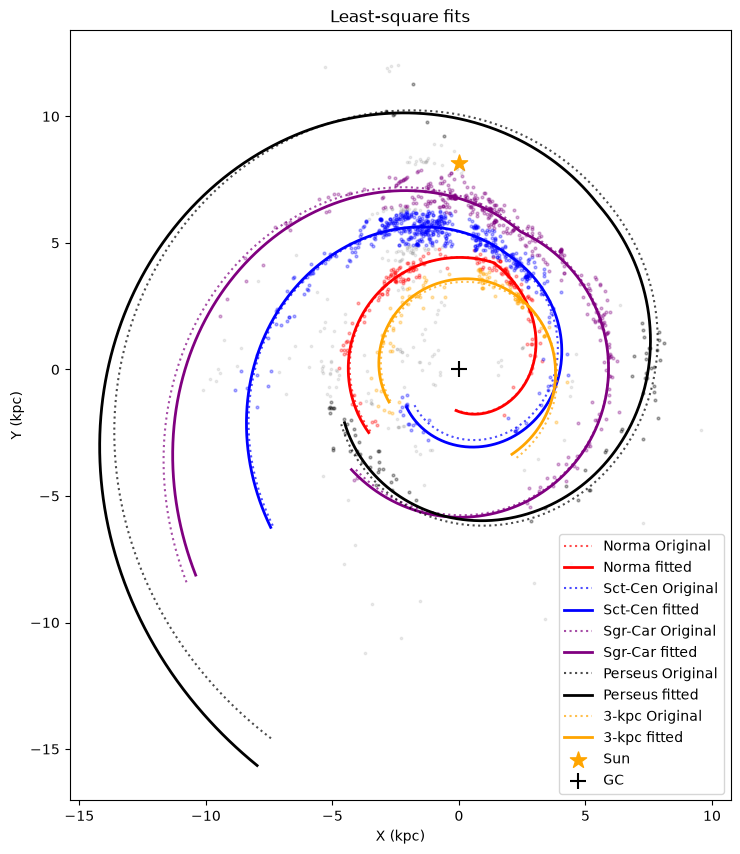

In [94]:
# Plot fitted arms

fig, ax = plt.subplots(figsize=(10, 10))

for name in arm_names:

    original = extended_arms[name]
    fitted = fitted_arms[name]

    # Initial Reid geometry
    ax.plot(
        original["X"],
        original["Y"],
        color=colours[name],
        ls=":",
        lw=1.5,
        alpha=0.7,
        label = f"{name} Original"
    )

    # Newly fitted geometry
    ax.plot(
        fitted["X"],
        fitted["Y"],
        color=colours[name],
        ls="-",
        lw=2,
        label=f"{name} fitted"
    )

    # Clouds assigned to this arm
    subset = df[df["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.3,
        rasterized=True
    )

unassigned = df[df["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

ax.scatter(0, R0, marker="*", s=150, color="orange", label="Sun")
ax.scatter(0, 0, marker="+", s=120, color="black", label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.set_title('Least-square fits')
ax.legend()
plt.show()

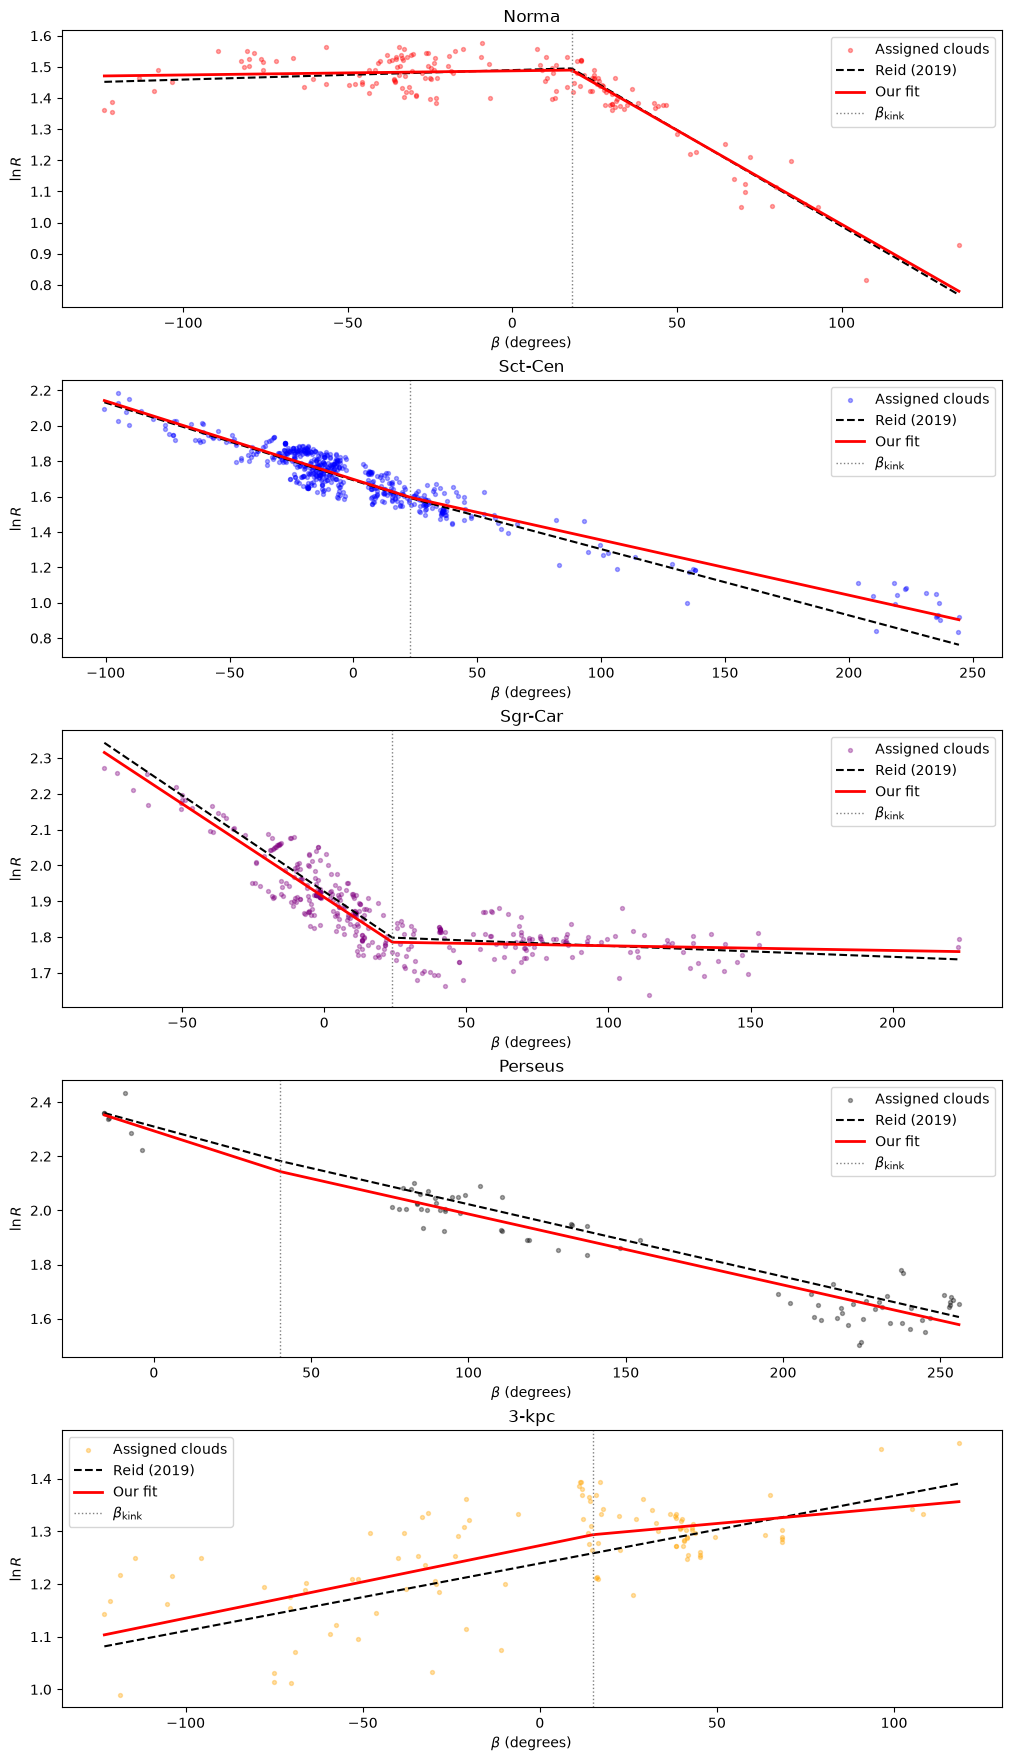

In [95]:
# Check fits of arms vs points (including both sides of the kink)

fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(10, 3.5 * len(arm_names)),
    constrained_layout=True
)

# Store fitted results for easy lookup
fit_lookup = {result["name"]: result for result in fit_results}

for ax, name in zip(axes, arm_names):

    # Clouds assigned to this arm
    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Grid covering the observed azimuth interval
    beta_grid = np.linspace(
        beta_cloud.min(),
        beta_cloud.max(),
        500
    )

    # Reid model: use the appropriate pitch angle on each side
    pitch_reid = np.where(
        beta_grid <= bkink,
        p_low,
        p_high
    )

    lnR_reid = (
        np.log(Rkink)
        - np.radians(beta_grid - bkink)
        * np.tan(np.radians(pitch_reid))
    )

    # Plot assigned clouds
    ax.scatter(
        beta_cloud,
        lnR_cloud,
        s=8,
        color=colours[name],
        alpha=0.35,
        label="Assigned clouds"
    )

    # Plot Reid model
    ax.plot(
        beta_grid,
        lnR_reid,
        "k--",
        lw=1.5,
        label="Reid (2019)"
    )

    # Plot our fitted model, if available
    result = fit_lookup.get(name)

    if result is not None:

        pitch_fit = np.where(
            beta_grid <= bkink,
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        lnR_fit = (
            np.log(result["Rkink_fit"])
            - np.radians(beta_grid - bkink)
            * np.tan(np.radians(pitch_fit))
        )

        ax.plot(
            beta_grid,
            lnR_fit,
            color="red",
            lw=2,
            label="Our fit"
        )

    # Mark Reid's kink if it lies within the plotted interval
    if beta_grid.min() <= bkink <= beta_grid.max():
        ax.axvline(
            bkink,
            color="gray",
            ls=":",
            lw=1,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(name)
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\ln R$")

    ax.legend()

plt.show()

In [96]:
# Turns out outliers impact the fit negatively even for the full sample. 
# Try a different fit, Huber loss. Similar to least squares but less sensitive to outliers

def fit_robust_arm(
    df, name, parameters,
    min_points=20,
    min_side_points=2,
    f_scale=0.03
):

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Select clouds assigned to this arm
    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ]

    if len(subset) < min_points:
        print('Not enough points!', name)
        return None

    beta = subset["beta_unwrapped_deg"].to_numpy(dtype=float)
    R = subset["R_kpc"].to_numpy(dtype=float)

    # Angular distance from kink, in radians
    x = np.radians(beta - bkink)
    y = np.log(R)

    # Separate the two sides of the kink
    x_low = np.minimum(x, 0.0)
    x_high = np.maximum(x, 0.0)

    n_low = np.sum(x <= 0)
    n_high = np.sum(x > 0)

    # Require adequate coverage on both sides
    if n_low < min_side_points or n_high < min_side_points:
        print('Not enough side points!', name, n_low, n_high)
        return None

    # Design matrix for continuous piecewise-linear model
    A = np.column_stack([
        np.ones_like(x),
        x_low,
        x_high
    ])

    # Initial solution from ordinary least squares
    theta0 = np.linalg.lstsq(A, y, rcond=None)[0]

    # Residuals in ln(R)
    def residuals(theta):
        return y - A @ theta

    # Robust fitting with Huber loss
    result = least_squares(
        residuals,
        x0=theta0,
        loss="huber",
        f_scale=f_scale
    )

    if not result.success:
        return None

    a_fit, m_low_fit, m_high_fit = result.x

    return {
        "name": name,
        "N": len(subset),
        "N_low": int(n_low),
        "N_high": int(n_high),

        "Rkink_fit": np.exp(a_fit),

        "pitch_low_fit": np.degrees(
            np.arctan(-m_low_fit)
        ),

        "pitch_high_fit": np.degrees(
            np.arctan(-m_high_fit)
        ),

        "Rkink_Reid": Rkink,
        "pitch_low_Reid": p_low,
        "pitch_high_Reid": p_high
    }

In [97]:
# Robust Huber fitting for all arms

robust_results = []

for name in arm_names:

    robust_result = fit_robust_arm(
        df,
        name,
        parameters,
        min_points=20,
        min_side_points=2,
        f_scale=0.03
    )

    if robust_result is not None:
        robust_results.append(robust_result)

robust_table = pd.DataFrame(robust_results)

if not robust_table.empty:
    print(robust_table.round(3).to_string(index=False))
else:
    print("No arms met the fitting requirements.")

   name   N  N_low  N_high  Rkink_fit  pitch_low_fit  pitch_high_fit  Rkink_Reid  pitch_low_Reid  pitch_high_Reid
  Norma 164    103      61      4.440         -0.208          19.367        4.46            -1.0             19.5
Sct-Cen 555    443     112      4.911         14.616          10.135        4.91            14.1             12.1
Sgr-Car 357    223     134      5.971         16.713           0.277        6.04            17.1              1.0
Perseus  79      7      72      8.517         11.886           8.620        8.87            10.3              8.7
  3-kpc 109     56      53      3.669         -4.132          -0.701        3.52            -4.2             -4.2


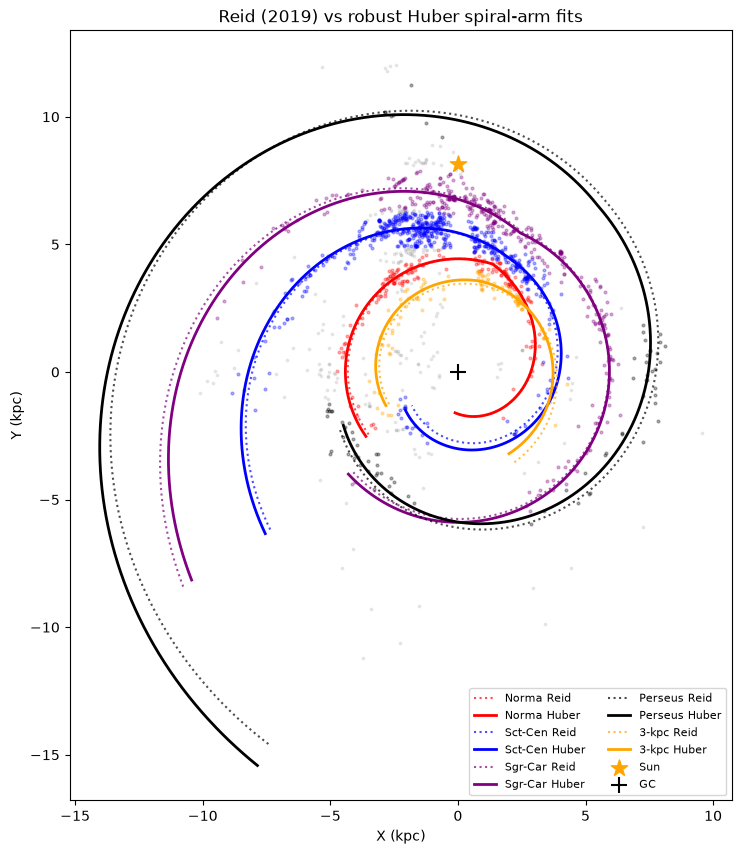

In [98]:
# Plot original Reid arms and robust Huber fits

fig, ax = plt.subplots(figsize=(10, 10))

# Lookup for robust fitting results
robust_lookup = {r["name"]: r for r in robust_results}

for name in arm_names:

    original = extended_arms[name]

    # Initial Reid geometry
    ax.plot(
        original["X"],
        original["Y"],
        color=colours[name],
        ls=":",
        lw=1.5,
        alpha=0.7,
        label=f"{name} Reid"
    )

    # Robust Huber fitted geometry
    result = robust_lookup.get(name)

    if result is not None:

        # Use the same unwrapped azimuth range as the Reid curve
        beta_grid = original["beta"]

        # Reid kink azimuth
        bkink = parameters[name][2]

        # Two-pitch-angle Huber model
        pitch = np.where(
            beta_grid <= bkink,
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        R_fit = result["Rkink_fit"] * np.exp(
            -np.radians(beta_grid - bkink)
            * np.tan(np.radians(pitch))
        )

        X_fit = R_fit * np.sin(np.radians(beta_grid))
        Y_fit = R_fit * np.cos(np.radians(beta_grid))

        ax.plot(
            X_fit,
            Y_fit,
            color=colours[name],
            ls="-",
            lw=2,
            label=f"{name} Huber"
        )

    # Clouds assigned to this arm
    subset = df[df["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.3,
        rasterized=True
    )

# Unassigned clouds
unassigned = df[df["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

# Sun and Galactic centre
ax.scatter(
    0, R0,
    marker="*",
    s=150,
    color="orange",
    label="Sun"
)

ax.scatter(
    0, 0,
    marker="+",
    s=120,
    color="black",
    label="GC"
)

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.set_title("Reid (2019) vs robust Huber spiral-arm fits")
ax.legend(fontsize=8, ncol=2)

plt.show()

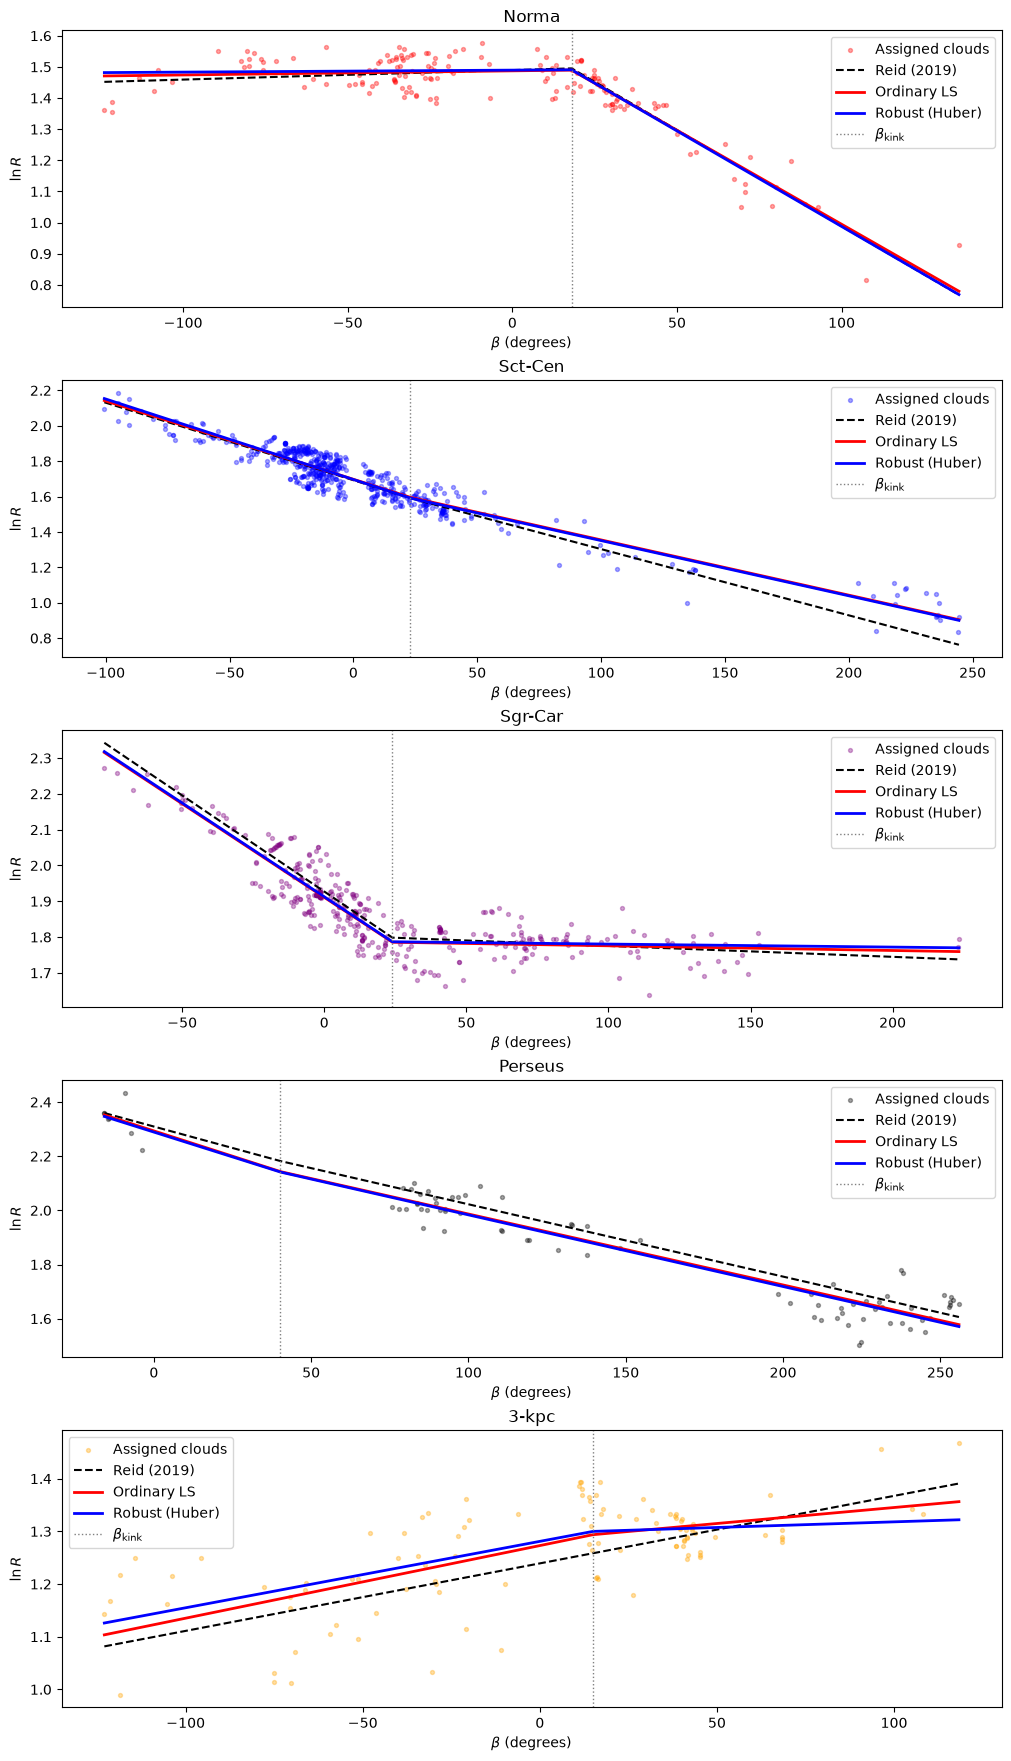

In [99]:
# Compare Reid, ordinary least squares, and robust fits

fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(10, 3.5 * len(arm_names)),
    constrained_layout=True,
    squeeze=False
)

axes = axes.ravel()

# Create lookup dictionaries
fit_lookup = {r["name"]: r for r in fit_results}
robust_lookup = {r["name"]: r for r in robust_results}

for ax, name in zip(axes, arm_names):

    # Select valid clouds assigned to this arm
    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Grid spanning the observed cloud azimuths
    # Include the kink explicitly if it lies within the interval
    beta_grid = np.linspace(
        beta_cloud.min(),
        beta_cloud.max(),
        500
    )

    if beta_grid.min() < bkink < beta_grid.max():
        beta_grid = np.sort(np.r_[beta_grid, bkink])

    # Helper: continuous two-pitch logarithmic spiral
    def model_lnR(beta, Rkink, pitch_low, pitch_high):
        pitch = np.where(
            beta <= bkink,
            pitch_low,
            pitch_high
        )

        return (
            np.log(Rkink)
            - np.radians(beta - bkink)
            * np.tan(np.radians(pitch))
        )

    # Reid model
    lnR_reid = model_lnR(
        beta_grid, Rkink, p_low, p_high
    )

    # Plot molecular clouds
    ax.scatter(
        beta_cloud,
        lnR_cloud,
        s=8,
        color=colours[name],
        alpha=0.35,
        label="Assigned clouds"
    )

    # Plot Reid model
    ax.plot(
        beta_grid,
        lnR_reid,
        "k--",
        lw=1.5,
        label="Reid (2019)"
    )

    # Ordinary least-squares fit
    result = fit_lookup.get(name)

    if result is not None:

        lnR_fit = model_lnR(
            beta_grid,
            result["Rkink_fit"],
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        ax.plot(
            beta_grid,
            lnR_fit,
            color="red",
            lw=2,
            label="Ordinary LS"
        )

    # Robust Huber fit
    result_robust = robust_lookup.get(name)

    if result_robust is not None:

        lnR_rob = model_lnR(
            beta_grid,
            result_robust["Rkink_fit"],
            result_robust["pitch_low_fit"],
            result_robust["pitch_high_fit"]
        )

        ax.plot(
            beta_grid,
            lnR_rob,
            color="blue",
            lw=2,
            label="Robust (Huber)"
        )

    # Mark the kink if covered by the observations
    if beta_grid.min() <= bkink <= beta_grid.max():
        ax.axvline(
            bkink,
            color="gray",
            ls=":",
            lw=1,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(name)
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\ln R$")

    ax.legend()

plt.show()


## Caution with these plots. For Perseus, Sct-Cen and Sgr-Car you see Reid missing them by a lot. That is a mistake, they are not at 
## azimuth -100 but actually at b > 100. if you take the same points, keep their lnR the same and move them to teh far right then
## they fit well!

In [100]:
## Investigate cloud-arm distance

# Look up fitted parameters
fit_lookup = {r["name"]: r for r in fit_results}
robust_lookup = {r["name"]: r for r in robust_results}

def spiral_xy(beta, bkink, Rkink, pitch_low, pitch_high):
    """
    Calculate Cartesian coordinates for a continuous
    two-pitch-angle logarithmic spiral.

    beta and pitch angles are in degrees.
    Radii and Cartesian coordinates are in kpc.
    """

    pitch = np.where(
        beta <= bkink,
        pitch_low,
        pitch_high
    )

    R = Rkink * np.exp(
        -np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )

    X = R * np.sin(np.radians(beta))
    Y = R * np.cos(np.radians(beta))

    return np.column_stack([X, Y])


def cloud_arm_distances(cloud_xy, beta_grid,
                        bkink, Rkink, pitch_low, pitch_high):

    arm_xy = spiral_xy(
        beta_grid, bkink, Rkink, pitch_low, pitch_high
    )

    tree = cKDTree(arm_xy)

    distances, _ = tree.query(cloud_xy)

    return distances

In [101]:
# Initialize distance columns
for model in ["Reid", "OLS", "Huber"]:
    df[f"residual_{model}_kpc"] = np.nan

for name in arm_names:

    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["X_kpc"])
        & np.isfinite(df["Y_kpc"])
        & np.isfinite(df["beta_unwrapped_deg"])
    ]

    if subset.empty:
        continue

    cloud_xy = subset[["X_kpc", "Y_kpc"]].to_numpy()  ## Array for all clouds assigned to an arm, not single cloud

    beta_cloud = subset["beta_unwrapped_deg"].to_numpy()

    # Same comparison interval for all models
    beta_grid = np.linspace(
        beta_cloud.min() - 5,
        beta_cloud.max() + 5,
        10000
    )

    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    models = {
        "Reid": (Rkink, p_low, p_high)
    }

    if name in fit_lookup:
        r = fit_lookup[name]
        models["OLS"] = (
            r["Rkink_fit"],
            r["pitch_low_fit"],
            r["pitch_high_fit"]
        )

    if name in robust_lookup:
        r = robust_lookup[name]
        models["Huber"] = (
            r["Rkink_fit"],
            r["pitch_low_fit"],
            r["pitch_high_fit"]
        )

    for model_name, (radius, pitch1, pitch2) in models.items():

        distances = cloud_arm_distances(  ## Array of all distances ofclouds associated to arm, with arm
            cloud_xy,
            beta_grid,
            bkink,
            radius,
            pitch1,
            pitch2
        )

        df.loc[
            subset.index,
            f"residual_{model_name}_kpc"
        ] = distances

In [102]:
comparison = []

for name in arm_names:

    subset = df[df["assigned_arm"] == name]

    width = arm_widths[name]

    for model in ["Reid", "OLS", "Huber"]:

        d = subset[f"residual_{model}_kpc"].dropna().to_numpy()

        if len(d) == 0:
            continue

        comparison.append({
            "Arm": name,
            "Model": model,
            "N": len(d),
            "Median_kpc": np.median(d),
            "RMS_kpc": np.sqrt(np.mean(d**2)),
            "Within_1w_%": 100 * np.mean(d <= width),
            "Within_2w_%": 100 * np.mean(d <= 2 * width)
        })

comparison_table = pd.DataFrame(comparison)

print(comparison_table.round(3).to_string(index=False))

    Arm Model   N  Median_kpc  RMS_kpc  Within_1w_%  Within_2w_%
  Norma  Reid 164       0.151    0.201       43.293       83.537
  Norma   OLS 164       0.154    0.199       43.902       83.537
  Norma Huber 164       0.155    0.200       44.512       82.317
Sct-Cen  Reid 555       0.262    0.342       45.946       77.297
Sct-Cen   OLS 555       0.244    0.334       47.387       80.180
Sct-Cen Huber 555       0.244    0.335       46.847       80.360
Sgr-Car  Reid 357       0.203    0.336       59.104       86.835
Sgr-Car   OLS 357       0.214    0.324       59.944       89.356
Sgr-Car Huber 357       0.220    0.324       59.944       91.036
Perseus  Reid  79       0.335    0.432       55.696       92.405
Perseus   OLS  79       0.293    0.387       67.089       92.405
Perseus Huber  79       0.277    0.389       63.291       92.405
  3-kpc  Reid 109       0.163    0.257       56.881       77.982
  3-kpc   OLS 109       0.136    0.237       56.881       85.321
  3-kpc Huber 109       0

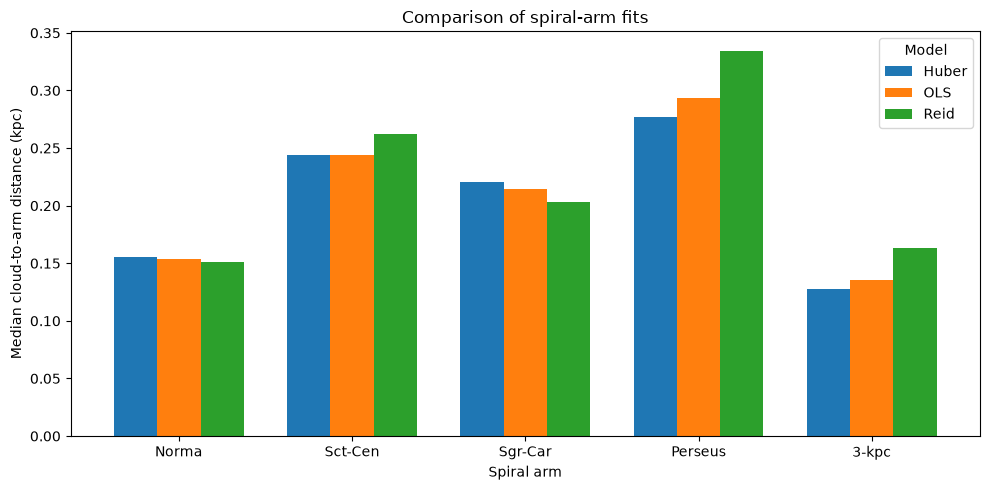

In [103]:
median_table = comparison_table.pivot(  # This turns the 15 x 1 column Median_kpc you see above into a 5 x 3 table, model vs arm
    index="Arm",
    columns="Model",
    values="Median_kpc"
)  

median_table = median_table.reindex(arm_names)

ax = median_table.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_ylabel("Median cloud-to-arm distance (kpc)")
ax.set_xlabel("Spiral arm")
ax.set_title("Comparison of spiral-arm fits")
ax.legend(title="Model")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

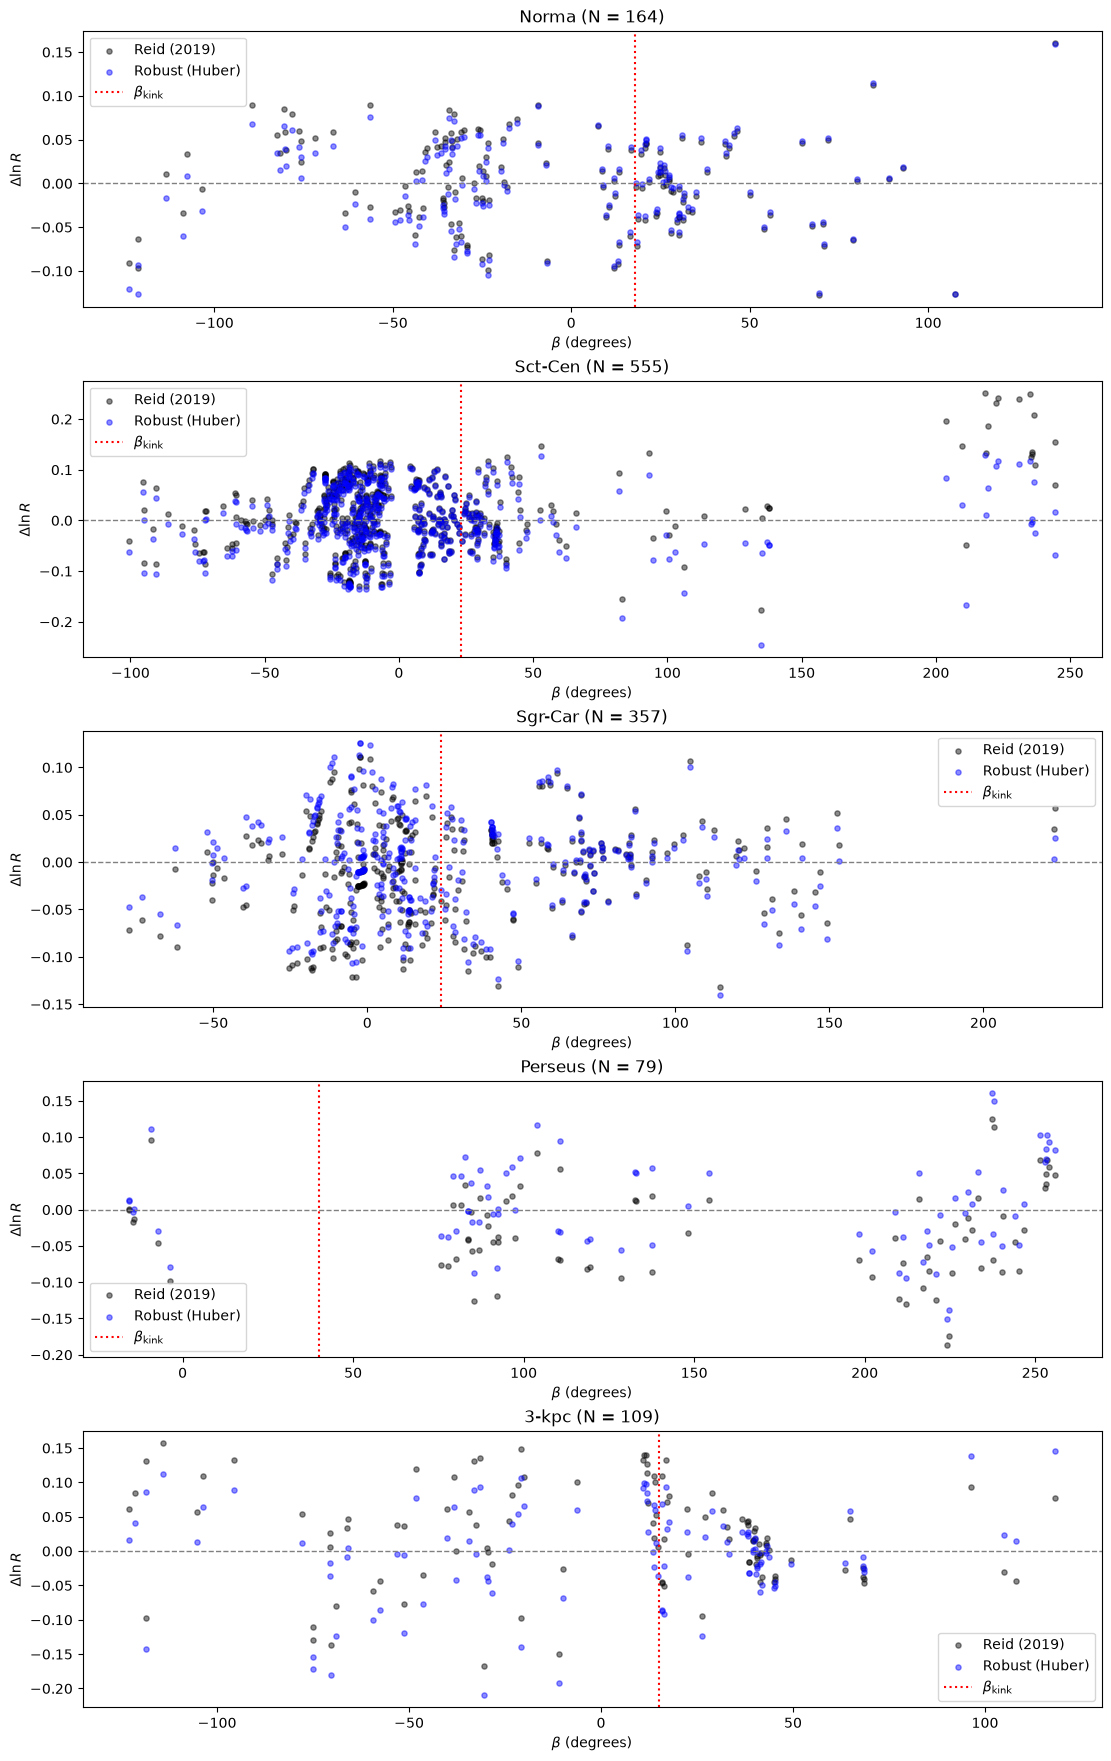

In [104]:
# Lookup for robust fitting results
# Plot the residuals, we want our points in the plots to be close to 0.
robust_lookup = {r["name"]: r for r in robust_results}

def spiral_lnR(beta, bkink, Rkink, pitch_low, pitch_high):
    """
    Logarithmic radius of a two-pitch-angle spiral.
    All angles are in degrees.
    """

    pitch = np.where(
        beta <= bkink,
        pitch_low,
        pitch_high
    )

    return (
        np.log(Rkink)
        - np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )


fig, axes = plt.subplots(
    len(arm_names), 1,
    figsize=(11, 3.5 * len(arm_names)),
    constrained_layout=True,
    squeeze=False
)

axes = axes.ravel()

for ax, name in zip(axes, arm_names):

    # Select valid clouds
    subset = df.loc[
        (df["assigned_arm"] == name)
        & np.isfinite(df["beta_unwrapped_deg"])
        & np.isfinite(df["R_kpc"])
        & (df["R_kpc"] > 0)
    ]

    if subset.empty:
        ax.set_title(f"{name} (no assigned clouds)")
        continue

    beta = subset["beta_unwrapped_deg"].to_numpy()
    lnR_cloud = np.log(subset["R_kpc"].to_numpy())

    # Original Reid parameters
    _, _, bkink, Rkink, p_low, p_high = parameters[name]

    # Reid predictions and residuals
    lnR_reid = spiral_lnR(
        beta, bkink, Rkink, p_low, p_high
    )

    residual_reid = lnR_cloud - lnR_reid

    ax.scatter(
        beta,
        residual_reid,
        s=14,
        color="black",
        alpha=0.45,
        label="Reid (2019)"
    )

    # Robust Huber predictions and residuals
    result = robust_lookup.get(name)

    if result is not None:

        lnR_huber = spiral_lnR(
            beta,
            bkink,
            result["Rkink_fit"],
            result["pitch_low_fit"],
            result["pitch_high_fit"]
        )

        residual_huber = lnR_cloud - lnR_huber

        ax.scatter(
            beta,
            residual_huber,
            s=14,
            color="blue",
            alpha=0.45,
            label="Robust (Huber)"
        )

    # Zero residual reference
    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    # Reid kink azimuth
    if beta.min() <= bkink <= beta.max():
        ax.axvline(
            bkink,
            color="red",
            linestyle=":",
            linewidth=1.5,
            label=r"$\beta_{\rm kink}$"
        )

    ax.set_title(f"{name} (N = {len(subset)})")
    ax.set_xlabel(r"$\beta$ (degrees)")
    ax.set_ylabel(r"$\Delta \ln R$")

    ax.legend()

plt.show()